# 04 — Are the models' results reliable? Five-fold cross-validation

**Question:** If we choose different training and validation examples, do the models still perform similarly?

We hold aside the original 20% **test set** untouched. Then we run five rounds of validation on only the 80% **training set**. Each round fits a fresh scaler **only on that round's training rows** so there is no data leakage. The model comes from `mlforge`, while scikit-learn supplies datasets and evaluation utilities.

- Diabetes: evaluate **R²** (higher is better) and compare with a mean-only predictor.
- Breast cancer: evaluate **accuracy** and compare with a majority-class predictor.

This notebook is educational and is not a clinical validation.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, accuracy_score
from mlforge import LinearRegression, LogisticRegression

RANDOM_STATE = 42
N_FOLDS = 5

## Part A — Linear Regression on diabetes

We split once into an outer training set (80%) and held-out test set (20%). Then `KFold` rotates the validation group through the 80% training set. Each fold must fit a fresh scaler and a fresh model. The baseline simply predicts the average progression of the fold's training samples.

In [2]:
diabetes = load_diabetes(as_frame=True, scaled=False)
X_d, y_d = diabetes.data, diabetes.target
X_d_train, X_d_test, y_d_train, y_d_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=RANDOM_STATE
)
rows_d = []
folds_d = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fold, (tr, va) in enumerate(folds_d.split(X_d_train), start=1):
    X_tr, X_va = X_d_train.iloc[tr], X_d_train.iloc[va]
    y_tr, y_va = y_d_train.iloc[tr], y_d_train.iloc[va]
    scaler = StandardScaler().fit(X_tr)  # Fit ONLY on this fold's training rows
    model = LinearRegression().fit(scaler.transform(X_tr), y_tr)
    predictions = model.predict(scaler.transform(X_va))
    baseline = np.repeat(float(y_tr.mean()), len(y_va))
    rows_d.append({
        "Fold": fold,
        "MLForge R²": r2_score(y_va, predictions),
        "Mean baseline R²": r2_score(y_va, baseline),
    })
cv_diabetes = pd.DataFrame(rows_d)
display(cv_diabetes.round(4))
print("Diabetes MLForge mean R²:", round(cv_diabetes["MLForge R²"].mean(), 4))
print("Diabetes MLForge SD of R²:", round(cv_diabetes["MLForge R²"].std(ddof=1), 4))

,Fold,MLForge R²,Mean baseline R²
0,1,0.4701,-0.0718
1,2,0.5368,-0.0282
2,3,0.4111,-0.0008
3,4,0.4913,-0.0255
4,5,0.4925,-0.0103


Diabetes MLForge mean R²: 0.4804
Diabetes MLForge SD of R²: 0.0457


## Part B — Logistic Regression on breast cancer

Use `StratifiedKFold` because we want each validation group to contain similar proportions of malignant (`0`) and benign (`1`) examples. The baseline always guesses the most frequent class of that round's training group.

In [3]:
cancer = load_breast_cancer(as_frame=True)
X_c, y_c = cancer.data, cancer.target
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_c, y_c, test_size=0.2, random_state=RANDOM_STATE, stratify=y_c
)
rows_c = []
folds_c = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
for fold, (tr, va) in enumerate(folds_c.split(X_c_train, y_c_train), start=1):
    X_tr, X_va = X_c_train.iloc[tr], X_c_train.iloc[va]
    y_tr, y_va = y_c_train.iloc[tr], y_c_train.iloc[va]
    scaler = StandardScaler().fit(X_tr)
    model = LogisticRegression(learning_rate=0.1, max_iter=2000).fit(
        scaler.transform(X_tr), y_tr
    )
    predictions = model.predict(scaler.transform(X_va))
    majority_label = int(y_tr.value_counts().idxmax())
    baseline = np.repeat(majority_label, len(y_va))
    rows_c.append({
        "Fold": fold,
        "MLForge accuracy": accuracy_score(y_va, predictions),
        "Majority baseline accuracy": accuracy_score(y_va, baseline),
    })
cv_cancer = pd.DataFrame(rows_c)
display(cv_cancer.round(4))
print("Cancer MLForge mean accuracy:", round(cv_cancer["MLForge accuracy"].mean(), 4))
print("Cancer MLForge SD of accuracy:", round(cv_cancer["MLForge accuracy"].std(ddof=1), 4))

,Fold,MLForge accuracy,Majority baseline accuracy
0,1,0.967,0.6264
1,2,0.989,0.6264
2,3,0.978,0.6264
3,4,0.989,0.6264
4,5,0.967,0.6264


Cancer MLForge mean accuracy: 0.978
Cancer MLForge SD of accuracy: 0.011


## Part C — Compare scores across rounds

Cross-validation results should be read as mean **and** variation. A high average with a large spread is less reassuring than a similarly high average with a small spread. The two metrics have different scales and must not be directly compared against each other.

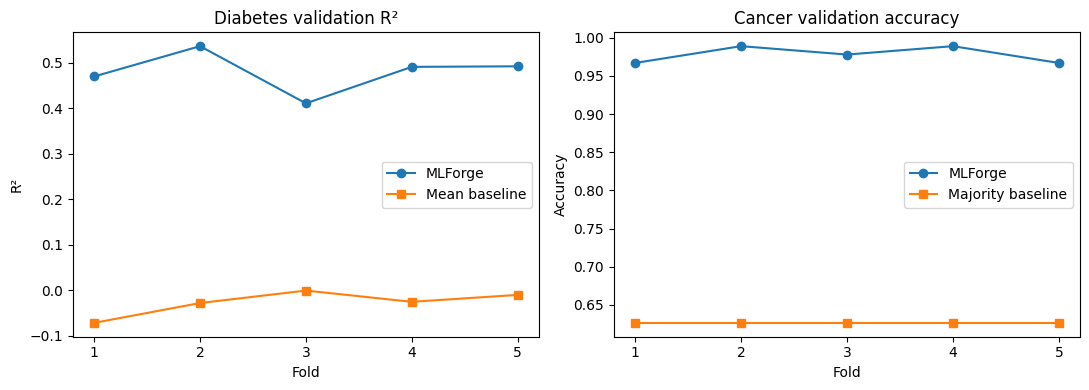

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(cv_diabetes["Fold"], cv_diabetes["MLForge R²"], marker="o", label="MLForge")
axes[0].plot(cv_diabetes["Fold"], cv_diabetes["Mean baseline R²"], marker="s", label="Mean baseline")
axes[0].set(title="Diabetes validation R²", xlabel="Fold", ylabel="R²", xticks=range(1, 6))
axes[0].legend()
axes[1].plot(cv_cancer["Fold"], cv_cancer["MLForge accuracy"], marker="o", label="MLForge")
axes[1].plot(cv_cancer["Fold"], cv_cancer["Majority baseline accuracy"], marker="s", label="Majority baseline")
axes[1].set(title="Cancer validation accuracy", xlabel="Fold", ylabel="Accuracy", xticks=range(1, 6))
axes[1].legend()
fig.tight_layout()
plt.show()

assert len(cv_diabetes) == N_FOLDS and len(cv_cancer) == N_FOLDS
assert np.all(np.isfinite(cv_diabetes.select_dtypes(include="number")))
assert np.all(np.isfinite(cv_cancer.select_dtypes(include="number")))

## Optional final check — Fit on all 80% training rows; evaluate the untouched 20% exactly once

Cross-validation is used to estimate variability, not to fit the final model. This final comparison reports the untouched hold-out results from the original setup. It should match the earlier notebooks, apart from floating-point rounding.

In [5]:
d_scaler = StandardScaler().fit(X_d_train)
d_final = LinearRegression().fit(d_scaler.transform(X_d_train), y_d_train)
d_test_r2 = d_final.score(d_scaler.transform(X_d_test), y_d_test)

c_scaler = StandardScaler().fit(X_c_train)
c_final = LogisticRegression(learning_rate=0.1, max_iter=2000).fit(
    c_scaler.transform(X_c_train), y_c_train
)
c_test_acc = c_final.score(c_scaler.transform(X_c_test), y_c_test)

print(f"Untouched diabetes test R²: {d_test_r2:.4f}")
print(f"Untouched cancer test accuracy: {c_test_acc:.2%}")

Untouched diabetes test R²: 0.4526
Untouched cancer test accuracy: 96.49%


## What this contribution demonstrates

- Data split choice can change measured accuracy and R².
- Rescaling must be learned only from each fold's training rows.
- Comparison to a simple baseline shows whether the model really adds predictive value.
- Validation folds are not the same as the final untouched test set.
